<a href="https://colab.research.google.com/github/tijanigambari2004-oss/TEEJAY-S-flower-classifier/blob/main/image_classifier_2_0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Folders found: ['LICENSE.txt', 'daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 3157s 19us/step


Saving ACCT8616.JPG to ACCT8616.JPG
Saving ACHC5858.JPG to ACHC5858.JPG
Saving ACVD6572.MP4 to ACVD6572.MP4
Saving AFVO6621.JPG to AFVO6621.JPG
Saving AJJB4769.JPG to AJJB4769.JPG
Saving AMEAE3915.JPG to AMEAE3915.JPG
Saving ANAK8514.MP4 to ANAK8514.MP4
Saving ANPX7948.JPG to ANPX7948.JPG
Saving ANZI1709.JPG to ANZI1709.JPG
Saving AOMI4224.JPG to AOMI4224.JPG
Saving AVRQ7972.JPG to AVRQ7972.JPG
Saving BLIA7876.JPG to BLIA7876.JPG
Saving BOSBE4425.JPG to BOSBE4425.JPG
Saving BPTN6851.JPG to BPTN6851.JPG
Skipped ACVD6572.MP4 - cannot identify image file 'ACVD6572.MP4'
Skipped ANAK8514.MP4 - cannot identify image file 'ANAK8514.MP4'
not_flower images: 712
Found 4382 files belonging to 6 classes.
Using 3506 files for training.
Found 4382 files belonging to 6 classes.
Using 876 files for validation.
['daisy', 'dandelion', 'not_flower', 'roses', 'sunflowers', 'tulips']
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
110/110 ━━━━━━━━━━━━━━━━━━━━ 21s 97ms/step - accuracy: 0.7310 - l

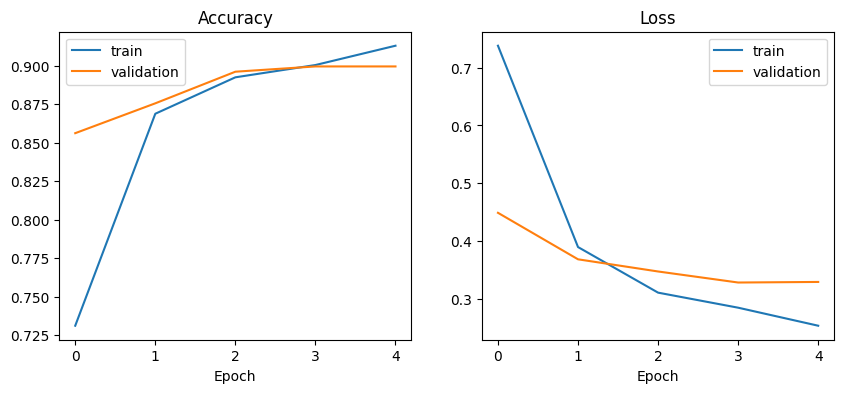

Saved: flower_classifier.keras
Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://b81904e189109cd09c.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Created dataset file at: .gradio/flagged/dataset1.csv


In [ ]:
# ===== 0. SETUP =====
!pip install -q gradio

import os, pathlib
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tensorflow import keras
from tensorflow.keras import layers
from google.colab import files
import gradio as gr

# ===== 1. DOWNLOAD FLOWERS + FIX THE FOLDER PATH =====
url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
data_dir = pathlib.Path(keras.utils.get_file("flower_photos", url, untar=True))
if (data_dir / "flower_photos").exists():
    data_dir = data_dir / "flower_photos"
print("Folders found:", sorted(os.listdir(data_dir)))

# ===== 2. CREATE THE "not_flower" CLASS (CIFAR-10 filler images) =====
out = data_dir / "not_flower"
out.mkdir(exist_ok=True)

(x_train, y_train), _ = keras.datasets.cifar10.load_data()
rng = np.random.default_rng(42)
idx = rng.choice(len(x_train), 700, replace=False)
for n, i in enumerate(idx):
    Image.fromarray(x_train[i]).resize((224, 224), Image.BICUBIC).save(out / f"cifar_{n}.jpg")

# ===== 3. ADD YOUR OWN NON-FLOWER PHOTOS (optional but recommended) =====
# Set to False to skip. Upload 20-50 photos of people, rooms, food, objects.
# Keep 5-10 photos aside on your computer to test with later.
UPLOAD_OWN_PHOTOS = True
if UPLOAD_OWN_PHOTOS:
    uploaded = files.upload()
    for k, filename in enumerate(uploaded.keys()):
        try:
            img = Image.open(filename)
            img = ImageOps.exif_transpose(img).convert("RGB").resize((224, 224))
            img.save(out / f"mine_{k}.jpg")
        except Exception as e:
            print("Skipped", filename, "-", e)
print("not_flower images:", len(os.listdir(out)))

# ===== 4. LOAD THE DATA (80% train / 20% validation) =====
train_ds = keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="training", seed=42,
    image_size=(224, 224), batch_size=32)
val_ds = keras.utils.image_dataset_from_directory(
    data_dir, validation_split=0.2, subset="validation", seed=42,
    image_size=(224, 224), batch_size=32)

class_names = train_ds.class_names
print(class_names)
assert len(class_names) == 6, f"Expected 6 classes, got {len(class_names)}: {class_names}"

# ===== 5. BUILD THE MODEL (transfer learning with MobileNetV2) =====
base = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base.trainable = False

augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

inputs = keras.Input(shape=(224, 224, 3))
x = augment(inputs)
x = keras.applications.mobilenet_v2.preprocess_input(x)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(len(class_names))(x)
model = keras.Model(inputs, outputs)

# ===== 6. TRAIN =====
model.compile(
    optimizer="adam",
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=["accuracy"])
history = model.fit(train_ds, validation_data=val_ds, epochs=5)

# ===== 7. EVALUATE =====
loss, accuracy = model.evaluate(val_ds)
print(f"\nValidation accuracy: {accuracy:.2%}")

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="train")
plt.plot(history.history["val_accuracy"], label="validation")
plt.title("Accuracy"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("Loss"); plt.xlabel("Epoch"); plt.legend()
plt.show()

# ===== 8. SAVE THE MODEL =====
model.save("flower_classifier.keras")
print("Saved: flower_classifier.keras")

# ===== 9. LAUNCH THE DEMO APP =====
def classify(img):
    if img is None:
        return None
    img = ImageOps.exif_transpose(img).convert("RGB").resize((224, 224))
    arr = np.expand_dims(np.array(img), axis=0)
    probs = tf.nn.softmax(model.predict(arr, verbose=0)[0]).numpy()
    return {class_names[i]: float(probs[i]) for i in range(len(class_names))}

demo = gr.Interface(
    fn=classify,
    inputs=gr.Image(type="pil", label="Upload a photo"),
    outputs=gr.Label(num_top_classes=6, label="Prediction"),
    title="Flower Classifier",
    description="Recognizes daisy, dandelion, roses, sunflowers, tulips, or not_flower.")

demo.launch(share=True, debug=True)

In [ ]:
files.download("flower_classifier.keras")